In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

In [3]:
y = np.array([[0], [1], [1], [0]], dtype=float)

In [4]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [5]:
np.random.seed(42)

W1 = np.random.randn(2, 4) * np.sqrt(2 / 2)
b1 = np.zeros((1, 4))

W2 = np.random.randn(4, 1) * np.sqrt(2 / 4)
b2 = np.zeros((1, 1))

learning_rate = 1.0
epochs = 20000
losses = []


In [6]:
for epoch in range(epochs):

    # Forward propagation
    Z1 = X @ W1 + b1
    A1 = sigmoid(Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    # Binary cross-entropy loss
    eps = 1e-9
    loss = -np.mean(
        y * np.log(A2 + eps) +
        (1 - y) * np.log(1 - A2 + eps)
    )
    losses.append(loss)

    # Backpropagation: output layer
    dZ2 = A2 - y
    dW2 = A1.T @ dZ2 / len(X)
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    # Backpropagation: hidden layer
    dZ1 = (dZ2 @ W2.T) * A1 * (1 - A1)
    dW1 = X.T @ dZ1 / len(X)
    db1_grad = np.mean(dZ1, axis=0, keepdims=True)

    # Gradient descent
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1_grad


In [7]:
hidden = sigmoid(X @ W1 + b1)
probabilities = sigmoid(hidden @ W2 + b2)

In [8]:
print("XOR Predictions:")
for inputs, probability, target in zip(X, probabilities, y):
    print(
        f"Input: {inputs.astype(int)} | "
        f"Probability: {probability[0]:.4f} | "
        f"Target: {int(target[0])}"
    )

print("\nFinal loss:", round(losses[-1], 6))

XOR Predictions:
Input: [0 0] | Probability: 0.0000 | Target: 0
Input: [0 1] | Probability: 0.9995 | Target: 1
Input: [1 0] | Probability: 0.9996 | Target: 1
Input: [1 1] | Probability: 0.0008 | Target: 0

Final loss: 0.000437


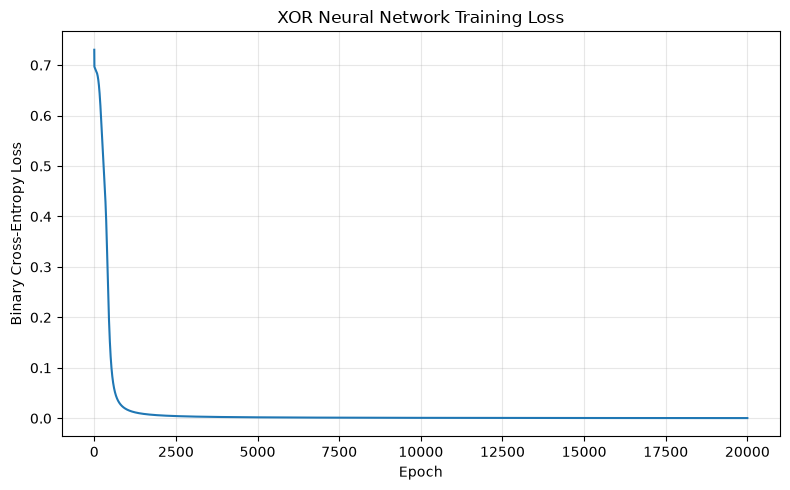

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("XOR Neural Network Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
